# Simulación Estocástica de Yahtzee con Método Monte Carlo
## Comprobación Experimental de la Ley de los Grandes Números (LLN), Bondad de Ajuste $\chi^2$ y Teorema del Límite Central (TLC)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Yahtzee-Montecarlo/blob/main/Simulacion_Yahtzee_Montecarlo_Colab.ipynb)
![Python Version](https://img.shields.io/badge/Python-3.10%2B-blue.svg)
![Institution](https://img.shields.io/badge/IU%20Digital%20de%20Antioquia-Grupo%2025-1E3A8A)

---
### Información Institucional
* **Asignatura:** Simulación (`PREICA2602B020045`) — Grupo 25
* **Actividad Didáctica 1 — Módulo 1:** Introducción a la Simulación (Ciclo **USA, MODIFICA y CREA**)
* **Docente Catedrático:** Julian Andres Loaiza Lopez
* **Integrantes del Equipo:**
  * Adriana Andrea Agudelo Agudelo
  * Camilo Alberto Palacios Turriago
  * Juan Daniel Pulgarin García
  * Ruben Dario Jaramillo Cervantes
* **Institución:** Institución Universitaria Digital de Antioquia (IU Digital) — Facultad de Ingeniería

> **Nota de Autocontención:** Este cuaderno es **100% autónomo**. No depende de archivos externos y puede ejecutarse íntegramente en Google Colab pulsando *Entorno de ejecución -> Ejecutar todas*.


---
## 1. Configuración Científica y Motor Vectorizado de Yahtzee ($|\Omega| = 6^5 = 7,776$)
Definimos las **13 categorías reglamentarias** (con *Full House* estricto `[2, 3]`, idéntico a `yahtzee_montecarlo.py`) y construimos la tabla exacta sobre los $7,776$ microestados equiprobables de $\Omega$.


In [1]:
import itertools
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 140})

CATEGORIAS_SUPERIORES = ['unos', 'doses', 'treses', 'cuatros', 'cincos', 'seises']
CATEGORIAS_INFERIORES = ['trio', 'poker', 'full', 'escalera_corta', 'escalera_larga', 'yahtzee', 'libre']
CATEGORIAS = CATEGORIAS_SUPERIORES + CATEGORIAS_INFERIORES
INDICE_CAT = {c: i for i, c in enumerate(CATEGORIAS)}
NUM_CAT = {'unos': 1, 'doses': 2, 'treses': 3, 'cuatros': 4, 'cincos': 5, 'seises': 6}
PESOS_B6 = np.array([1296, 216, 36, 6, 1], dtype=np.int32)
MASCARAS_ARRAY = np.array([[(num >> i) & 1 == 1 for i in range(5)] for num in range(32)], dtype=bool)

def hay_escalera(mano, largo):
    u = sorted(set(mano))
    r_act = r_max = 1
    for i in range(1, len(u)):
        r_act = r_act + 1 if u[i] == u[i - 1] + 1 else 1
        r_max = max(r_max, r_act)
    return r_max >= largo

def calcular_puntos(cat, mano):
    c = Counter(mano)
    rep = list(c.values())
    s = sum(mano)
    if cat in NUM_CAT: return c[NUM_CAT[cat]] * NUM_CAT[cat]
    if cat == 'trio': return s if max(rep) >= 3 else 0
    if cat == 'poker': return s if max(rep) >= 4 else 0
    if cat == 'full': return 25 if sorted(rep) == [2, 3] else 0
    if cat == 'escalera_corta': return 30 if hay_escalera(mano, 4) else 0
    if cat == 'escalera_larga': return 40 if hay_escalera(mano, 5) else 0
    if cat == 'yahtzee': return 50 if max(rep) == 5 else 0
    if cat == 'libre': return s
    return 0

# Precalcular tabla exacta sobre los 7,776 estados de Omega
TABLA_PUNTOS = np.zeros((7776, 13), dtype=np.int32)
CLASE_PARTICION = np.zeros(7776, dtype=np.int8)
MAPA_PART = {(5,): 0, (1,4): 1, (2,3): 2, (1,1,3): 3, (1,2,2): 4, (1,1,1,2): 5, (1,1,1,1,1): 6}
for idx, tiro in enumerate(itertools.product(range(1, 7), repeat=5)):
    m = list(tiro)
    CLASE_PARTICION[idx] = MAPA_PART[tuple(sorted(Counter(m).values()))]
    for j, cat in enumerate(CATEGORIAS):
        TABLA_PUNTOS[idx, j] = calcular_puntos(cat, m)

def codificar_b6(arr):
    return np.tensordot(arr - 1, PESOS_B6, axes=([-1], [0])).astype(np.int32)

print(f'Motor inicializado con éxito: |Omega| = {len(TABLA_PUNTOS):,} estados x {len(CATEGORIAS)} categorías.')


Motor inicializado con éxito: |Omega| = 7,776 estados x 13 categorías.


---
## 2. Deducción Combinatoria Exacta de las 13 Categorías
Verificamos sobre el espacio completo $\Omega$ la fracción exacta $P(A) = |A|/7,776$ para cada categoría.


In [2]:
filas_teor = []
for j, cat in enumerate(CATEGORIAS):
    fav = int((TABLA_PUNTOS[:, j] > 0).sum())
    prob = fav / 7776
    filas_teor.append({
        'Categoría': cat,
        'Casos Favorables': fav,
        'Espacio |Omega|': 7776,
        'P Teórica': round(prob, 6),
        '% Teórico': round(prob * 100, 4),
        'EV 1 Tiro (pts)': round(float(TABLA_PUNTOS[:, j].mean()), 3),
    })
df_teorico = pd.DataFrame(filas_teor)
display(df_teorico)


Categoría,Casos Favorables,Espacio |Omega|,P Teórica,% Teórico,EV 1 Tiro (pts)
unos,4651,7776,0.598122,59.8122,0.833
doses,4651,7776,0.598122,59.8122,1.667
treses,4651,7776,0.598122,59.8122,2.500
cuatros,4651,7776,0.598122,59.8122,3.333
cincos,4651,7776,0.598122,59.8122,4.167
seises,4651,7776,0.598122,59.8122,5.000
trio,1656,7776,0.212963,21.2963,3.727
poker,156,7776,0.020062,2.0062,0.351
full,300,7776,0.038580,3.8580,0.965
escalera_corta,1200,7776,0.154321,15.4321,4.630


---
## 3. Ley de los Grandes Números ($N = 100,000$) y Bondad de Ajuste $\chi^2$
Simulamos $100,000$ lanzamientos independientes evaluando las **13 categorías reales**, distinguiendo la **Fase Transitoria ($N \le 200$)** frente al **Estado Estable**, y validamos el generador PCG64 mediante pruebas $\chi^2$.


Prueba Chi² Uniformidad (500,000 dados, gl=5): Chi² = 2.7491, p-valor = 0.7386
Prueba Chi² Partición Omega (100,000 manos, gl=6): Chi² = 1.2740, p-valor = 0.9731


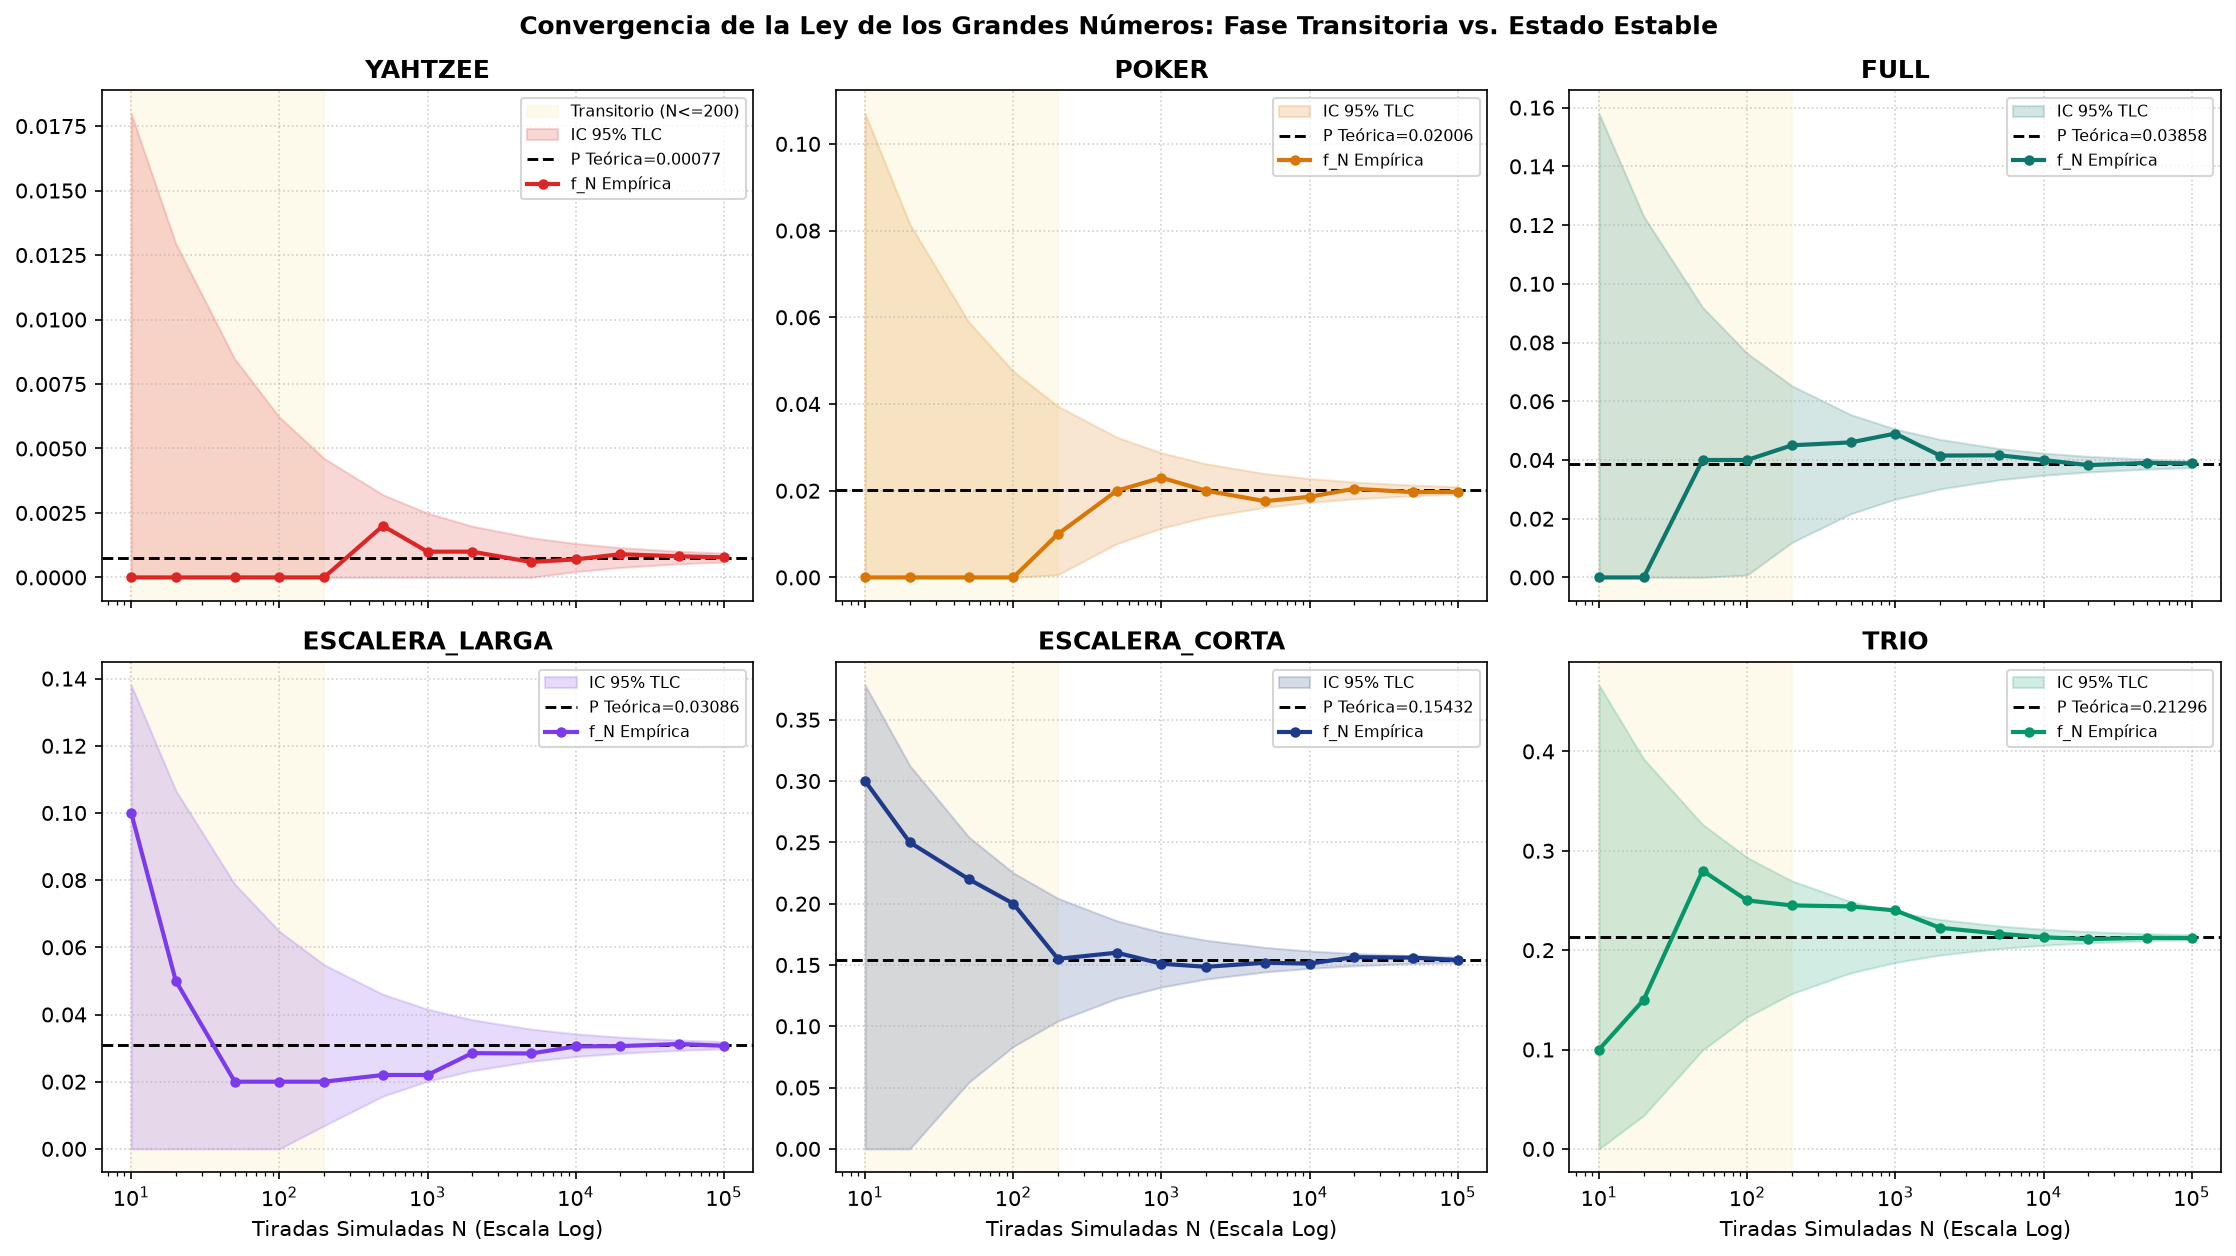

In [3]:
rng_lln = np.random.default_rng(42)
N_TOTAL = 100_000
checkpoints = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000]
tiradas_100k = rng_lln.integers(1, 7, size=(N_TOTAL, 5))
codigos_100k = codificar_b6(tiradas_100k)
indicadores_13 = TABLA_PUNTOS[codigos_100k] > 0

# Pruebas Chi-Cuadrado de uniformidad y partición de Omega
obs_caras = np.bincount(tiradas_100k.ravel(), minlength=7)[1:]
chi2_u, p_u = stats.chisquare(obs_caras, np.full(6, 5 * N_TOTAL / 6.0))
obs_part = np.bincount(CLASE_PARTICION[codigos_100k], minlength=7)
esp_part = np.array([6, 150, 300, 1200, 1800, 3600, 720], dtype=float) * (N_TOTAL / 7776.0)
chi2_p, p_p = stats.chisquare(obs_part, esp_part)
print(f'Prueba Chi² Uniformidad (500,000 dados, gl=5): Chi² = {chi2_u:.4f}, p-valor = {p_u:.4f}')
print(f'Prueba Chi² Partición Omega (100,000 manos, gl=6): Chi² = {chi2_p:.4f}, p-valor = {p_p:.4f}')

cats_graf = ['yahtzee', 'poker', 'full', 'escalera_larga', 'escalera_corta', 'trio']
colores = ['#DC2626', '#D97706', '#0F766E', '#7C3AED', '#1E3A8A', '#059669']
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True)
for idx, (cat, col) in enumerate(zip(cats_graf, colores)):
    ax = axes.flatten()[idx]
    j = INDICE_CAT[cat]
    p_t = (TABLA_PUNTOS[:, j] > 0).mean()
    f_vals = [indicadores_13[:n, j].mean() for n in checkpoints]
    ci_l = [max(0.0, p_t - 1.96 * np.sqrt(p_t*(1-p_t)/n)) for n in checkpoints]
    ci_u = [min(1.0, p_t + 1.96 * np.sqrt(p_t*(1-p_t)/n)) for n in checkpoints]
    ax.axvspan(10, 200, color='#FEF3C7', alpha=0.35, label='Transitorio (N<=200)' if idx==0 else None)
    ax.fill_between(checkpoints, ci_l, ci_u, color=col, alpha=0.18, label='IC 95% TLC')
    ax.axhline(p_t, color='black', ls='--', lw=1.4, label=f'P Teórica={p_t:.5f}')
    ax.plot(checkpoints, f_vals, color=col, marker='o', ms=4, lw=2, label='f_N Empírica')
    ax.set_xscale('log')
    ax.set_title(cat.upper(), fontweight='bold')
    ax.grid(True, ls=':', alpha=0.6)
    ax.legend(fontsize=7.5, loc='upper right')
for i in range(3, 6): axes.flatten()[i].set_xlabel('Tiradas Simuladas N (Escala Log)')
fig.suptitle('Convergencia de la Ley de los Grandes Números: Fase Transitoria vs. Estado Estable', fontweight='bold')
plt.tight_layout()
plt.show()


---
## 4. Verificación del Teorema del Límite Central (TLC) y Pendiente OLS Log-Log
Comprobamos con $200$ réplicas independientes por nivel $N$ que el error estándar decae con pendiente $\approx -0.50$ en escala log-log.


Pendiente OLS Log-Log (Full House): m = -0.4775 (Teórica = -0.5000), R² = 0.9954


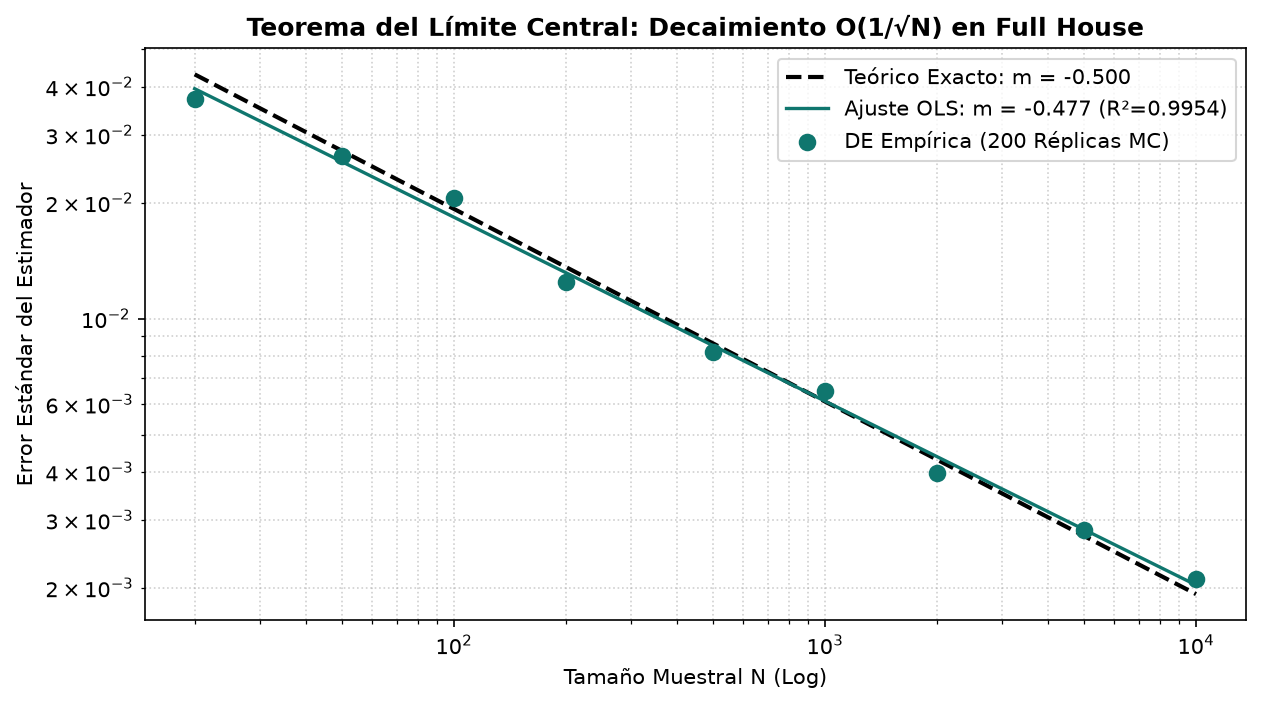

In [4]:
rng_tlc = np.random.default_rng(123)
n_lista = [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
REPLICAS = 200
j_full = INDICE_CAT['full']
p_full = (TABLA_PUNTOS[:, j_full] > 0).mean()
std_emp, std_teo = [], []
for n in n_lista:
    cods = codificar_b6(rng_tlc.integers(1, 7, size=(REPLICAS, n, 5)))
    est = (TABLA_PUNTOS[cods, j_full] > 0).mean(axis=1)
    std_emp.append(np.std(est, ddof=1))
    std_teo.append(np.sqrt(p_full * (1 - p_full) / n))

reg = stats.linregress(np.log10(n_lista), np.log10(std_emp))
print(f'Pendiente OLS Log-Log (Full House): m = {reg.slope:.4f} (Teórica = -0.5000), R² = {reg.rvalue**2:.4f}')

plt.figure(figsize=(8.5, 4.8))
plt.plot(n_lista, std_teo, 'k--', lw=2, label='Teórico Exacto: m = -0.500')
plt.plot(n_lista, 10**(reg.intercept + reg.slope*np.log10(n_lista)), color='#0F766E', lw=1.6, label=f'Ajuste OLS: m = {reg.slope:.3f} (R²={reg.rvalue**2:.4f})')
plt.scatter(n_lista, std_emp, color='#0F766E', s=55, zorder=4, label='DE Empírica (200 Réplicas MC)')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Tamaño Muestral N (Log)'); plt.ylabel('Error Estándar del Estimador')
plt.title('Teorema del Límite Central: Decaimiento O(1/√N) en Full House', fontweight='bold')
plt.grid(True, which='both', ls=':', alpha=0.6); plt.legend(); plt.tight_layout(); plt.show()


---
## 5. Estabilización del Valor Esperado (EV) en Decisiones Tácticas
Analizamos la mano `[3, 4, 4, 6, 1]` con casillas abiertas `{'cuatros', 'trio', 'full', 'escalera_larga', 'yahtzee'}`, midiendo cómo muestras pequeñas ($N=10$) inducen inversiones de rango y cómo $N \ge 250$ estabiliza la jugada óptima.


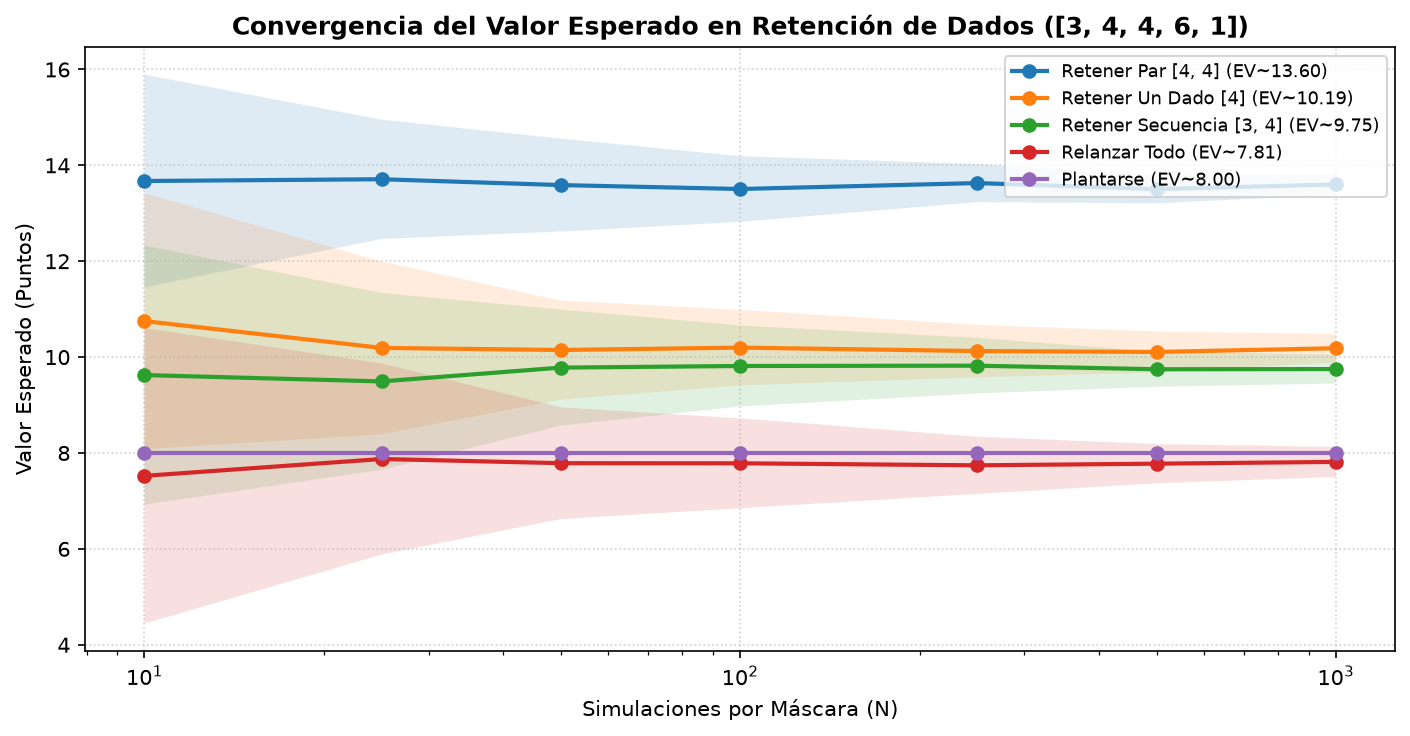

In [5]:
mano_p = np.array([3, 4, 4, 6, 1], dtype=np.int32)
cols_lib = [INDICE_CAT[c] for c in ['cuatros', 'trio', 'full', 'escalera_larga', 'yahtzee']]
mascaras_eval = {
    'Retener Par [4, 4]': np.array([False, True, True, False, False]),
    'Retener Un Dado [4]': np.array([False, True, False, False, False]),
    'Retener Secuencia [3, 4]': np.array([True, True, False, False, False]),
    'Relanzar Todo': np.array([False, False, False, False, False]),
    'Plantarse': np.array([True, True, True, True, True]),
}
sims_niveles = [10, 25, 50, 100, 250, 500, 1000]
rng_ev = np.random.default_rng(42)
plt.figure(figsize=(9.5, 5.0))
for nom, m_arr in mascaras_eval.items():
    medias, stds = [], []
    for ns_val in sims_niveles:
        if m_arr.all():
            val = float(TABLA_PUNTOS[codificar_b6(mano_p), cols_lib].max())
            medias.append(val); stds.append(0.0)
        else:
            az = rng_ev.integers(1, 7, size=(100, ns_val, 5))
            sim_m = np.where(m_arr, mano_p, az)
            pts = TABLA_PUNTOS[codificar_b6(sim_m)][:, :, cols_lib].max(axis=2).mean(axis=1)
            medias.append(pts.mean()); stds.append(pts.std(ddof=1))
    medias, stds = np.array(medias), np.array(stds)
    plt.plot(sims_niveles, medias, marker='o', lw=2, label=f'{nom} (EV~{medias[-1]:.2f})')
    plt.fill_between(sims_niveles, medias - stds, medias + stds, alpha=0.14)
plt.xscale('log'); plt.xlabel('Simulaciones por Máscara (N)'); plt.ylabel('Valor Esperado (Puntos)')
plt.title('Convergencia del Valor Esperado en Retención de Dados ([3, 4, 4, 6, 1])', fontweight='bold')
plt.grid(True, ls=':', alpha=0.6); plt.legend(loc='upper right', fontsize=8.5); plt.tight_layout(); plt.show()


---
## 6. Torneo Masivo de Partidas Completas (Aleatorio vs. Heurístico vs. IA Monte Carlo)
Simulamos un torneo completo autocontenido de **1,500 partidas oficiales de 13 rondas** ($500$ por estrategia) comparando las tres políticas de decisión.


Estrategia,Partidas,Media (pts),Desv. Estándar,Mediana,Tasa Bono (+35),Máximo
Aleatorio,500,44.90,17.62,41.0,0.0%,112
Heuristico,500,138.43,35.31,136.5,1.4%,236
Montecarlo,500,217.08,36.78,211.0,14.4%,329


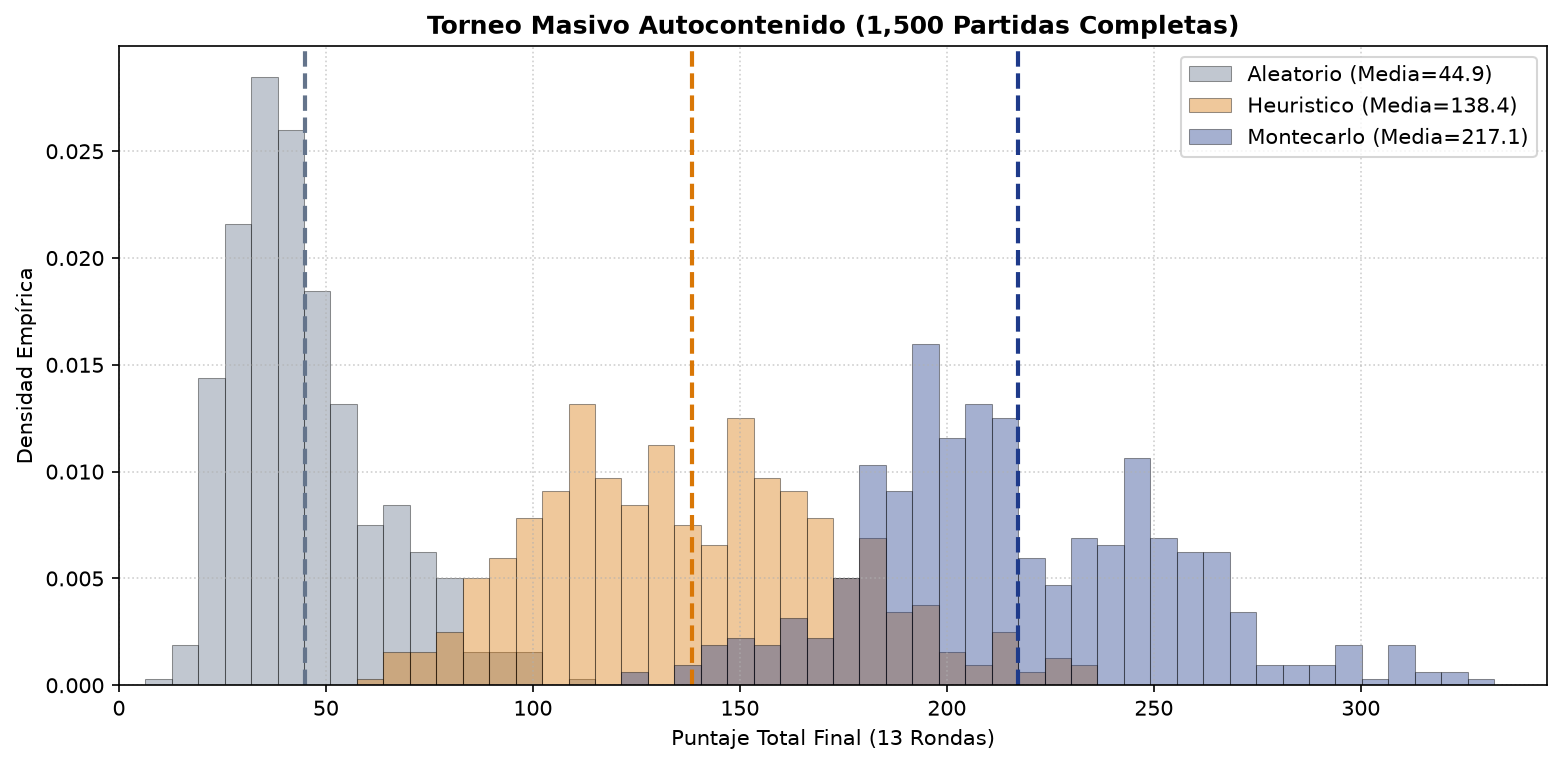

In [6]:
# Construir tabla de utilidad estratégica para el Agente IA Monte Carlo
UTILIDAD = TABLA_PUNTOS.astype(np.float64).copy()
for j, cat in enumerate(CATEGORIAS_SUPERIORES):
    cara = NUM_CAT[cat]
    k_d = TABLA_PUNTOS[:, j] // cara
    desv = (k_d - 3) * cara
    UTILIDAD[:, j] += np.where(k_d >= 3, 3.5 + 0.75 * desv, 0.90 * desv)
for cat, pen in {'trio':-7.0, 'poker':-10.5, 'full':-11.5, 'escalera_corta':-12.5, 'escalera_larga':-13.5, 'yahtzee':-14.5}.items():
    j = INDICE_CAT[cat]
    UTILIDAD[:, j] = np.where(TABLA_PUNTOS[:, j] == 0, pen, TABLA_PUNTOS[:, j] + 3.0)
UTILIDAD[:, INDICE_CAT['libre']] = TABLA_PUNTOS[:, INDICE_CAT['libre']] - 7.5
MASKS_3D = MASCARAS_ARRAY[:, None, :]

def simular_partida(agente, rng, sims_ev=80):
    tarjeta = {}
    for _ in range(13):
        libres = [c for c in CATEGORIAS if c not in tarjeta]
        lib_idx = [INDICE_CAT[c] for c in libres]
        dados = rng.integers(1, 7, size=5, dtype=np.int32)
        for _tiro in range(2):
            if agente == 'aleatorio':
                mask = MASCARAS_ARRAY[int(rng.integers(0, 32))]
            elif agente == 'heuristico':
                val_mc, frec_mc = Counter(dados.tolist()).most_common(1)[0]
                if frec_mc >= 2:
                    mask = (dados == val_mc)
                else:
                    mask = np.isin(dados, [5, 6])
            else:
                az = rng.integers(1, 7, size=(1, sims_ev, 5), dtype=np.int32)
                cods = codificar_b6(np.where(MASKS_3D, dados, az))
                evs = UTILIDAD[cods][:, :, lib_idx].max(axis=2).mean(axis=1)
                mask = MASCARAS_ARRAY[int(np.argmax(evs))]
            if mask.all(): break
            dados = np.where(mask, dados, rng.integers(1, 7, size=5, dtype=np.int32))
        idx_f = int(codificar_b6(dados))
        if agente == 'aleatorio':
            c_sel = str(rng.choice(libres))
        elif agente == 'heuristico':
            c_sel = libres[int(np.argmax(TABLA_PUNTOS[idx_f, lib_idx]))]
        else:
            c_sel = libres[int(np.argmax(UTILIDAD[idx_f, lib_idx]))]
        tarjeta[c_sel] = int(TABLA_PUNTOS[idx_f, INDICE_CAT[c_sel]])
    sup = sum(tarjeta[c] for c in CATEGORIAS_SUPERIORES)
    bono = 35 if sup >= 63 else 0
    inf = sum(tarjeta[c] for c in CATEGORIAS_INFERIORES)
    return sup + bono + inf, bono > 0

rng_torneo = np.random.default_rng(42)
N_JUEGOS = 500
datos_t, resumen_t = {}, []
for ag in ['aleatorio', 'heuristico', 'montecarlo']:
    res_ag = [simular_partida(ag, rng_torneo) for _ in range(N_JUEGOS)]
    pts = np.array([r[0] for r in res_ag])
    bonos = np.array([r[1] for r in res_ag])
    datos_t[ag] = pts
    resumen_t.append({
        'Estrategia': ag.capitalize(),
        'Partidas': N_JUEGOS,
        'Media (pts)': round(float(pts.mean()), 2),
        'Desv. Estándar': round(float(pts.std(ddof=1)), 2),
        'Mediana': float(np.median(pts)),
        'Tasa Bono (+35)': f'{bonos.mean()*100:.1f}%',
        'Máximo': int(pts.max()),
    })
display(pd.DataFrame(resumen_t))

plt.figure(figsize=(10.5, 5.2))
bins = np.linspace(0, 345, 55)
cols_ag = {'aleatorio': '#64748B', 'heuristico': '#D97706', 'montecarlo': '#1E3A8A'}
for ag in ['aleatorio', 'heuristico', 'montecarlo']:
    p = datos_t[ag]
    plt.hist(p, bins=bins, density=True, alpha=0.40, color=cols_ag[ag], edgecolor='black', lw=0.5, label=f'{ag.capitalize()} (Media={p.mean():.1f})')
    plt.axvline(p.mean(), color=cols_ag[ag], ls='--', lw=2)
plt.xlim(0, 345); plt.xlabel('Puntaje Total Final (13 Rondas)'); plt.ylabel('Densidad Empírica')
plt.title('Torneo Masivo Autocontenido (1,500 Partidas Completas)', fontweight='bold')
plt.grid(True, ls=':', alpha=0.6); plt.legend(); plt.tight_layout(); plt.show()


---
## 7. Reflexión Epistemológica: Aprendizaje y Desaprendizaje en Simulación

* **Lo que tuvimos que desaprender:**
  1. *El sesgo del software como fin en sí mismo:* Desaprendimos la idea de que construir la interfaz gráfica del juego equivale a resolver un proyecto de simulación. La aplicación es el vehículo experimental; la evidencia cuantitativa es el corazón científico.
  2. *La confianza en muestras pequeñas y heurísticas codiciosas:* Comprobamos que $N=10$ induce inversiones de rango severas y que perseguir intuitivamente solo pares destruye las escaleras y el Bono Superior.
* **El aprendizaje genuino construido:**
  1. Verificación empírica directa de la **Ley de los Grandes Números** (fase transitoria vs. estado estable) y validación formal del generador mediante pruebas $\chi^2$.
  2. Comprobación log-log del **Teorema del Límite Central** ($m \approx -0.50$) y diseño de políticas estocásticas óptimas basadas en **Valor Esperado (EV)**.
